# Block E — Community structure vs influence
### Where the SNA half and the IM half of the project meet

Blocks A-D described the network. Section 2 found the influential users. **Block E asks whether
those two things agree** - and that is the most interesting question in the whole analysis.

Three questions:
1. **Do CELF's seeds spread across communities, or cluster in one?**
   Spreading = submodularity working, the algorithm refusing to waste budget on overlapping audiences.
2. **Does any centrality measure actually predict influence?**
   If PageRank correlated perfectly with simulated spread, nobody would need CELF.
3. **Are seeds drawn from the structural core, or from bridges between groups?**

### Prerequisites
- `celf_seeds.csv` from the Section 2 **production** run (30 seeds, not the 5-seed smoke test)
- `data/gephi_node_metrics.csv` with a `Modularity Class` column

In [7]:
import pandas as pd, numpy as np, networkx as nx, random, time
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"font.size":11})
SEED=42; CRN_SEED=12345
random.seed(SEED); np.random.seed(SEED)

edges=pd.read_csv("data/gephi_edges.csv")
G=nx.DiGraph()
for r in edges.itertuples(index=False): G.add_edge(r.Source,r.Target,weight=int(r.Weight))
n=G.number_of_nodes()

seeds_df=pd.read_csv("celf_seeds.csv")
S_celf=(seeds_df[seeds_df.is_seed=="SEED"]
        .sort_values("seed_rank",ascending=False)["Id"].tolist())
print(f"loaded {len(S_celf)} CELF seeds")
if len(S_celf)<10:
    print("*** WARNING: fewer than 10 seeds - this looks like the QUICK_TEST run.")
    print("    Re-run influence_maximization_HN.ipynb with QUICK_TEST=False first. ***")

metrics=pd.read_csv("data/gephi_node_metrics.csv")
idc="Id" if "Id" in metrics.columns else metrics.columns[0]

def find_col(df, *keys, exclude=()):
    """Match a column regardless of Gephi naming style.
    Gephi may export display names ('PageRank') or internal ids ('pageranks')."""
    for c in df.columns:
        n=c.lower().replace(" ","").replace("_","").replace("-","")
        if any(x in n for x in exclude): continue
        if all(k in n for k in keys): return c
    return None

COLS={"modularity": find_col(metrics,"modularity"),
      "pagerank":   find_col(metrics,"pagerank"),
      "betweenness":find_col(metrics,"between"),
      "eigenvector":find_col(metrics,"eigen"),
      "closeness":  find_col(metrics,"clos", exclude=("harmonic",))}

print("COLUMNS DETECTED IN data/gephi_node_metrics.csv")
for k,v in COLS.items():
    print(f"  {k:<12} -> {v if v else 'NOT FOUND'}")
missing=[k for k,v in COLS.items() if v is None]
if missing:
    print(f"\n  missing: {missing}")
    print("  Run section1b_local_metrics.ipynb to generate all of them, then re-run this notebook.")
print(f"\nactual columns in file: {list(metrics.columns)}")

if COLS["modularity"] is None:
    raise SystemExit("no modularity column - run Louvain first (section1b or Gephi)")
comm=dict(zip(metrics[idc],metrics[COLS["modularity"]]))
print(f"\ncommunities: {len(set(comm.values()))}")

loaded 30 CELF seeds
COLUMNS DETECTED IN data/gephi_node_metrics.csv
  modularity   -> modularity_class
  pagerank     -> pageranks
  betweenness  -> betweenesscentrality
  eigenvector  -> eigencentrality
  closeness    -> closnesscentrality

actual columns in file: ['Id', 'Label', 'in_degree', 'out_degree', 'total_degree', 'weighted_in', 'weighted_out', 'indegree', 'outdegree', 'Degree', 'weighted indegree', 'weighted outdegree', 'Weighted Degree', 'modularity_class', 'pageranks', 'eigencentrality', 'Eccentricity', 'closnesscentrality', 'harmonicclosnesscentrality', 'betweenesscentrality', 'is_seed', 'seed_rank']

communities: 8


## E1 — Which communities do the seeds fall in?

If seeds concentrate in one community, the algorithm is over-covering one audience. If they
spread, it is deliberately reaching disjoint groups. Compare the seed distribution against what
you would expect if seeds were allocated purely in proportion to community size.

In [8]:
sizes=Counter(comm.values())
seed_comm=Counter(comm.get(v) for v in S_celf)
k=len(S_celf)

rows=[]
for cid,size in sorted(sizes.items(), key=lambda x:-x[1]):
    got=seed_comm.get(cid,0)
    exp=k*size/n
    rows.append({"community":cid,"nodes":size,"share_of_network":round(100*size/n,1),
                 "seeds":got,"expected_if_proportional":round(exp,2),
                 "over_under":round(got-exp,2)})
edf=pd.DataFrame(rows)
display(edf)
edf.to_csv("figures/blockE_seed_community_distribution.csv",index=False)

covered=len([x for x in seed_comm if x is not None])
big=[cid for cid,s in sizes.items() if s>=20]
print(f"\nseeds occupy {covered} of {len(big)} substantial communities")
print(f"most seeds in any one community: {max(seed_comm.values())} of {k}")
if max(seed_comm.values())/k > 0.6:
    print(">>> CLUSTERED: seeds concentrate in one community")
else:
    print(">>> SPREAD: seeds distribute across communities - consistent with submodularity")
    print("    avoiding redundant coverage of the same audience")

,community,nodes,share_of_network,seeds,expected_if_proportional,over_under
0,2,1614,25.1,12,7.53,4.47
1,0,1427,22.2,6,6.65,-0.65
2,3,1069,16.6,5,4.98,0.02
3,5,737,11.5,3,3.44,-0.44
4,4,504,7.8,0,2.35,-2.35
5,1,434,6.7,1,2.02,-1.02
6,7,424,6.6,2,1.98,0.02
7,6,225,3.5,1,1.05,-0.05



seeds occupy 7 of 8 substantial communities
most seeds in any one community: 12 of 30
>>> SPREAD: seeds distribute across communities - consistent with submodularity
    avoiding redundant coverage of the same audience


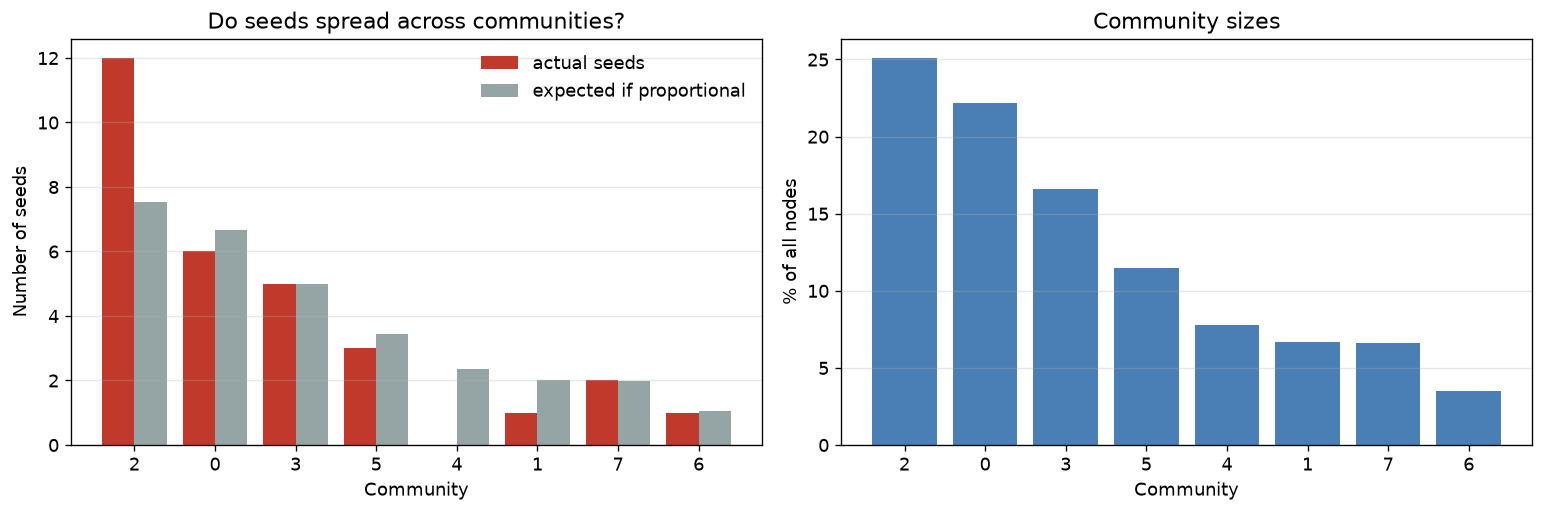

In [9]:
fig,ax=plt.subplots(1,2,figsize=(13,4.4))
cids=[r["community"] for r in rows]; x=np.arange(len(cids))
ax[0].bar(x-0.2,[r["seeds"] for r in rows],0.4,label="actual seeds",color="#c0392b")
ax[0].bar(x+0.2,[r["expected_if_proportional"] for r in rows],0.4,
          label="expected if proportional",color="#95a5a6")
ax[0].set_xticks(x); ax[0].set_xticklabels(cids)
ax[0].set_xlabel("Community"); ax[0].set_ylabel("Number of seeds")
ax[0].set_title("Do seeds spread across communities?")
ax[0].legend(frameon=False); ax[0].grid(alpha=.3,axis="y")

ax[1].bar(x,[r["share_of_network"] for r in rows],color="#4a7fb5")
ax[1].set_xticks(x); ax[1].set_xticklabels(cids)
ax[1].set_xlabel("Community"); ax[1].set_ylabel("% of all nodes")
ax[1].set_title("Community sizes"); ax[1].grid(alpha=.3,axis="y")
plt.tight_layout(); plt.savefig("figures/fig_E_seed_communities.png",bbox_inches="tight"); plt.show()

## E2 — Does centrality predict influence?

For a sample of nodes we simulate actual influence spread, then correlate that against each
centrality measure. **A high correlation means the cheap heuristic is a good proxy; a low one
means CELF is earning its cost.**

In [10]:
P={}
for u,v in G.edges():
    d=G.in_degree(v); P[(u,v)]=min(1.0/d,0.5) if d>0 else 0.5
ADJ={u:[(v,P[(u,v)]) for v in G.successors(u)] for u in G.nodes()}

def sample_worlds(adj,mc,seed):
    rng=random.Random(seed)
    return [{u:[v for v,p in nb if rng.random()<p] for u,nb in adj.items()} for _ in range(mc)]
def sigma(W,S):
    tot=0
    for live in W:
        act=set(S); fr=list(S)
        while fr:
            nxt=[]
            for u in fr:
                for v in live[u]:
                    if v not in act: act.add(v); nxt.append(v)
            fr=nxt
        tot+=len(act)
    return tot/len(W)

MC=150
W=sample_worlds(ADJ,MC,CRN_SEED)
SAMPLE=400
random.seed(SEED)
samp=random.sample(list(G.nodes()),SAMPLE)
t=time.time()
spread={v:sigma(W,[v]) for v in samp}
print(f"simulated single-node spread for {SAMPLE} nodes in {time.time()-t:.1f}s")

df=pd.DataFrame({"Id":samp})
df["actual_spread"]=df.Id.map(spread)
df["degree"]=df.Id.map(lambda v:G.in_degree(v)+G.out_degree(v))
df["out_degree"]=df.Id.map(dict(G.out_degree()))
for new in ["pagerank","betweenness","eigenvector","closeness"]:
    col=COLS.get(new)
    if col:
        df[new]=df.Id.map(dict(zip(metrics[idc],metrics[col])))
    else:
        print(f"  (skipping {new} - not in metrics file)")

meas=[x for x in ["degree","out_degree","pagerank","betweenness","eigenvector","closeness"]
      if x in df.columns]
corr=df[["actual_spread"]+meas].corr(method="spearman")["actual_spread"].drop("actual_spread")
corr=corr.sort_values(ascending=False)
print("\nSpearman correlation with ACTUAL simulated influence spread:")
for m,v in corr.items(): print(f"  {m:<14} {v:6.3f}")
corr.to_frame("spearman_vs_spread").to_csv("figures/blockE_centrality_vs_spread.csv")

simulated single-node spread for 400 nodes in 0.4s

Spearman correlation with ACTUAL simulated influence spread:
  out_degree      0.847
  closeness       0.791
  degree          0.791
  betweenness     0.765
  pagerank        0.668
  eigenvector     0.655


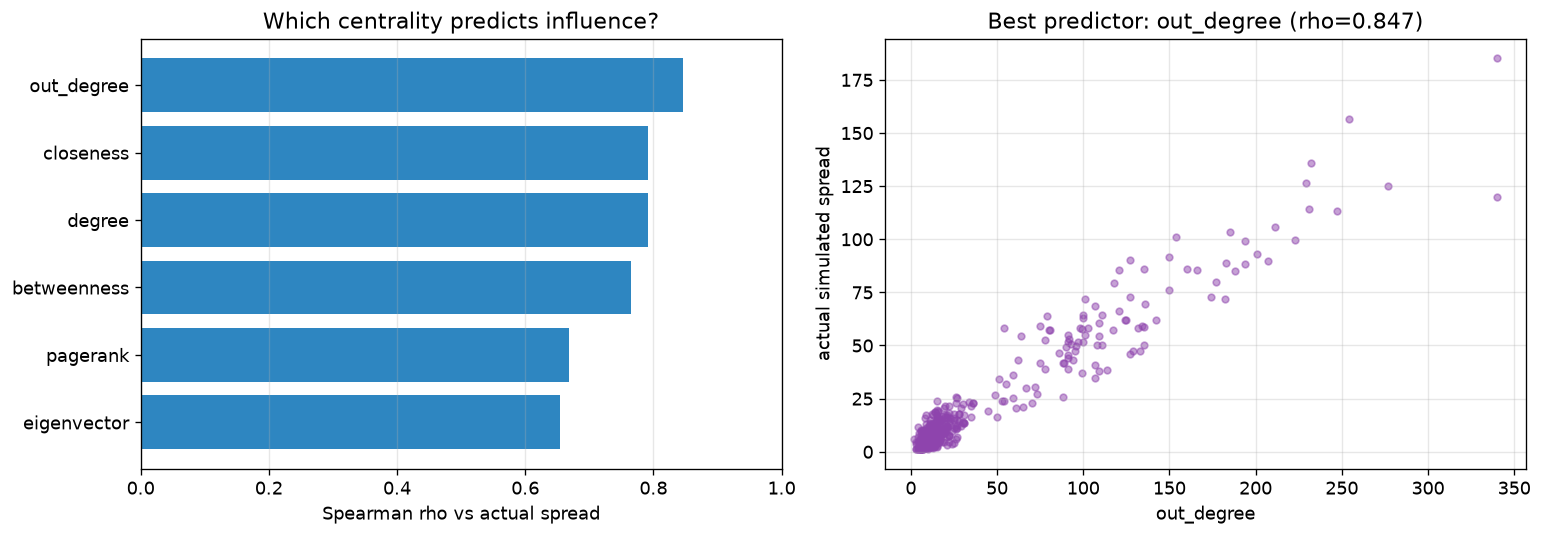

In [11]:
fig,ax=plt.subplots(1,2,figsize=(13,4.6))
ax[0].barh(corr.index[::-1],corr.values[::-1],color="#2e86c1")
ax[0].set_xlabel("Spearman rho vs actual spread")
ax[0].set_title("Which centrality predicts influence?")
ax[0].grid(alpha=.3,axis="x"); ax[0].set_xlim(0,1)

best=corr.index[0]
ax[1].scatter(df[best],df.actual_spread,s=16,alpha=.5,color="#8e44ad")
ax[1].set_xlabel(best); ax[1].set_ylabel("actual simulated spread")
ax[1].set_title(f"Best predictor: {best} (rho={corr.iloc[0]:.3f})")
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/fig_E_centrality_vs_spread.png",bbox_inches="tight"); plt.show()

## E3 — What kind of nodes are the seeds?

Percentile ranks of the seeds on each measure. This tells you whether CELF picks the obvious
hubs or something structurally subtler.

In [12]:
prof=metrics[metrics[idc].isin(S_celf)].copy()
deg=dict(G.degree()); out=dict(G.out_degree())
prof["degree"]=prof[idc].map(deg); prof["out_degree"]=prof[idc].map(out)

print("SEED PROFILE - percentile rank within the network")
checks=[("degree",None),("out_degree",None)]
for nm in ["pagerank","betweenness","eigenvector","closeness"]:
    if COLS.get(nm): checks.append((nm, COLS[nm]))

for nm,col in checks:
    if col is None:
        allv=pd.Series(deg if nm=="degree" else out)
    else:
        allv=metrics.set_index(idc)[col].dropna()
    vals=[allv.get(s) for s in S_celf]
    pct=[100*(allv < v).mean() for v in vals if v is not None and not pd.isna(v)]
    if pct:
        print(f"  {nm:<14} median percentile {np.median(pct):5.1f}  (min {min(pct):.0f}, max {max(pct):.0f})")

print("\nTOP 10 SEEDS")
show=[idc, COLS["modularity"], "degree"]
if COLS.get("pagerank"): show.append(COLS["pagerank"])
show=[x for x in show if x and x in prof.columns]
display(prof[prof[idc].isin(S_celf[:10])][show])
prof.to_csv("figures/blockE_seed_profile.csv",index=False)

SEED PROFILE - percentile rank within the network
  degree         median percentile  99.7  (min 98, max 100)
  out_degree     median percentile  99.8  (min 99, max 100)
  pagerank       median percentile  99.4  (min 81, max 100)
  betweenness    median percentile  99.7  (min 96, max 100)
  eigenvector    median percentile  99.0  (min 80, max 100)
  closeness      median percentile  99.8  (min 99, max 100)

TOP 10 SEEDS


,Id,modularity_class,degree,pageranks
14,u_68f80fcfd8cc,0,692,0.001213
19,u_9c2bfcf65852,2,964,0.001074
128,u_7645c5aa9d5f,0,2328,0.005272
160,u_e883ed61b279,1,706,0.001277
163,u_da4611ffd982,2,823,0.001447
535,u_8f9687ab44a4,0,804,0.001251
615,u_0cb2e49a48bf,5,846,0.001467
701,u_e188ab5477b9,0,476,0.000451
733,u_26277852db5b,2,711,0.001037
881,u_e983e1de91c6,2,781,0.001077


## What to write up

Take the three numbers this produced:

1. **Seed spread across communities** (E1) - clustered or spread, and what that says about
   submodularity. Remember your modularity Q was only ~0.13, so communities barely separate -
   interpret accordingly rather than over-claiming.
2. **Best centrality correlation with actual spread** (E2) - if it is well below 1.0, that is your
   evidence that centrality is not influence, and that the optimisation is doing real work.
3. **Seed percentile profile** (E3) - are seeds simply the top-degree nodes, or not?

These three findings are what connect your network analysis to your influence-maximisation
results. Most reports present the two halves separately and never join them.

In [13]:
# ===== E4: DIRECTIONAL MISMATCH =====
from scipy.stats import spearmanr

nodes_all = list(G.nodes())
ind_all   = dict(G.in_degree())
outd_all  = dict(G.out_degree())

def _sp(a, b):
    return spearmanr([a[x] for x in nodes_all], [b[x] for x in nodes_all]).statistic

print("WHY PAGERANK UNDERPERFORMS: it measures the wrong direction\n")
print(f"{'measure':<14} {'vs IN-degree':>13} {'vs OUT-degree':>14}")
rows_dir = []
for nm in ["pagerank", "eigenvector", "betweenness", "closeness"]:
    col = COLS.get(nm)
    if not col:
        continue
    vals = dict(zip(metrics[idc], metrics[col]))
    vals = {x: vals.get(x) for x in nodes_all}
    if any(v is None or pd.isna(v) for v in vals.values()):
        print(f"{nm:<14} {'(has NaNs - skipped)':>28}")
        continue
    a, b = _sp(vals, ind_all), _sp(vals, outd_all)
    rows_dir.append({"measure": nm, "vs_in_degree": round(a, 3),
                     "vs_out_degree": round(b, 3), "gap": round(a - b, 3)})
    print(f"{nm:<14} {a:>13.3f} {b:>14.3f}")

print(f"\n{'in-degree vs out-degree':<14} {_sp(ind_all, outd_all):.3f}")
print("\nINTERPRETATION")
print("  Influence propagates along OUT-edges under the IC model.")
print("  A measure that tracks in-degree more closely than out-degree is ranking by")
print("  'who receives attention' rather than 'who reaches others' - the wrong direction.")

if rows_dir:
    pd.DataFrame(rows_dir).to_csv("figures/blockE_directional_mismatch.csv", index=False)
    print("\nsaved figures/blockE_directional_mismatch.csv")

WHY PAGERANK UNDERPERFORMS: it measures the wrong direction

measure         vs IN-degree  vs OUT-degree
pagerank               0.982          0.746
eigenvector            0.953          0.742
betweenness            0.906          0.889
closeness              0.754          0.927

in-degree vs out-degree 0.766

INTERPRETATION
  Influence propagates along OUT-edges under the IC model.
  A measure that tracks in-degree more closely than out-degree is ranking by
  'who receives attention' rather than 'who reaches others' - the wrong direction.

saved figures/blockE_directional_mismatch.csv


REDUNDANCY TEST - top-k by out-degree
If seeds reach DIFFERENT people, joint spread ~ sum of individual spreads.
If they reach the SAME people, joint spread falls far below the sum.

   k  sum(individual)   joint spread   overlap lost
   5             1381            808          41.5%
  10             2229           1027          53.9%
  20             3769           1323          64.9%
  30             5306           1515          71.4%

INTERPRETATION
  Overlap rising with k means the top-degree users keep reaching the SAME audience.
  This is submodularity - diminishing returns - measured directly on our network.
  It is why a heuristic can correlate well with INDIVIDUAL influence yet still
  choose a poor SET: it has no mechanism to avoid redundant coverage.
  CELF evaluates marginal gain given seeds already chosen, so it avoids this.


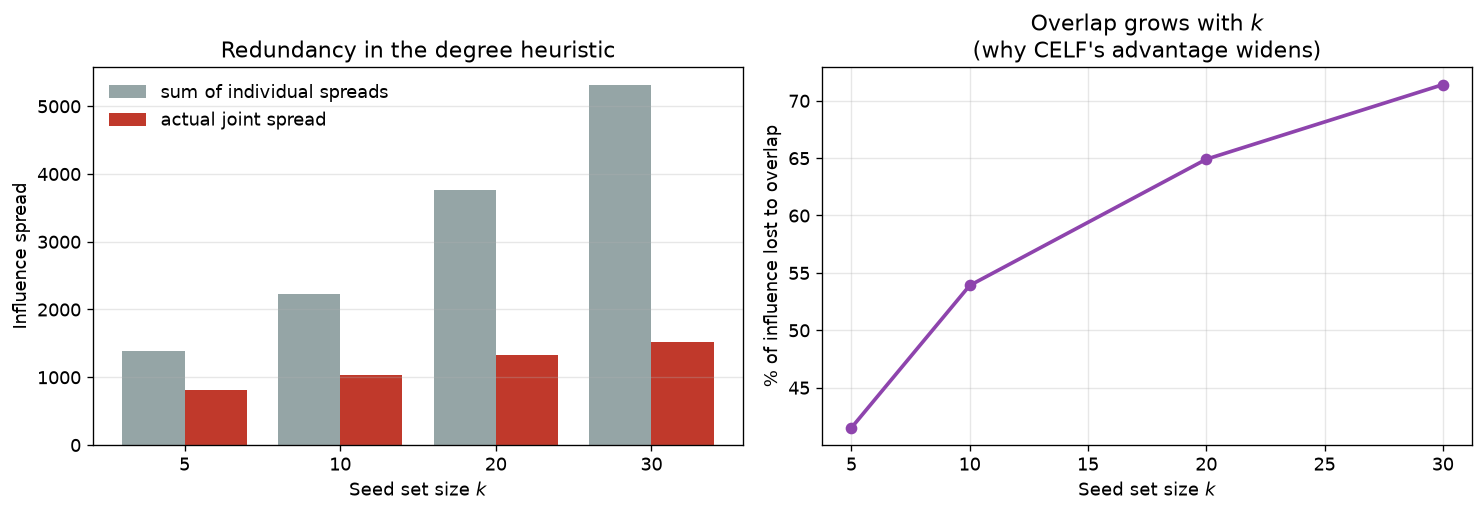


saved figures/fig_E_redundancy.png


In [14]:
# ===== E5: REDUNDANCY / SUBMODULARITY =====
K_TEST = [5, 10, 20, 30]
outd_map = dict(G.out_degree())
ranked = sorted(G.nodes(), key=lambda x: -outd_map[x])

indiv_cache = {}
def indiv(v):
    if v not in indiv_cache:
        indiv_cache[v] = sigma(W, [v])
    return indiv_cache[v]

print("REDUNDANCY TEST - top-k by out-degree")
print("If seeds reach DIFFERENT people, joint spread ~ sum of individual spreads.")
print("If they reach the SAME people, joint spread falls far below the sum.\n")
print(f"{'k':>4} {'sum(individual)':>16} {'joint spread':>14} {'overlap lost':>14}")

red_rows = []
for k in K_TEST:
    if k > len(ranked):
        continue
    S = ranked[:k]
    s_ind = sum(indiv(v) for v in S)
    s_joint = sigma(W, S)
    lost = 100 * (1 - s_joint / s_ind) if s_ind else 0
    red_rows.append({"k": k, "sum_individual": round(s_ind, 1),
                     "joint_spread": round(s_joint, 1), "overlap_lost_pct": round(lost, 1)})
    print(f"{k:>4} {s_ind:>16.0f} {s_joint:>14.0f} {lost:>13.1f}%")

red = pd.DataFrame(red_rows)
red.to_csv("figures/blockE_redundancy.csv", index=False)

print("\nINTERPRETATION")
print("  Overlap rising with k means the top-degree users keep reaching the SAME audience.")
print("  This is submodularity - diminishing returns - measured directly on our network.")
print("  It is why a heuristic can correlate well with INDIVIDUAL influence yet still")
print("  choose a poor SET: it has no mechanism to avoid redundant coverage.")
print("  CELF evaluates marginal gain given seeds already chosen, so it avoids this.")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
x = np.arange(len(red))
ax[0].bar(x - 0.2, red.sum_individual, 0.4, label="sum of individual spreads", color="#95a5a6")
ax[0].bar(x + 0.2, red.joint_spread, 0.4, label="actual joint spread", color="#c0392b")
ax[0].set_xticks(x); ax[0].set_xticklabels(red.k)
ax[0].set_xlabel("Seed set size $k$"); ax[0].set_ylabel("Influence spread")
ax[0].set_title("Redundancy in the degree heuristic")
ax[0].legend(frameon=False); ax[0].grid(alpha=.3, axis="y")

ax[1].plot(red.k, red.overlap_lost_pct, marker="o", lw=2.2, color="#8e44ad")
ax[1].set_xlabel("Seed set size $k$"); ax[1].set_ylabel("% of influence lost to overlap")
ax[1].set_title("Overlap grows with $k$\n(why CELF's advantage widens)")
ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig("figures/fig_E_redundancy.png", bbox_inches="tight")
plt.show()
print("\nsaved figures/fig_E_redundancy.png")